In [1]:
!pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   --------------------- ------------------ 5.2/9.7 MB 35.6 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.7 MB 34.6 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 24.2 MB/s  0:00:00


In [2]:
!pip install yfinance

  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 19.6 MB/s  0:00:00
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)

   ---------------------------------------- 0/6 [pytz]
   ---------------------------------------- 0/6 [pytz]
   ------ --------------------------------- 1/6 [websockets]
   ------ --------------------------------- 1/6 [websockets]
   ------------- -------------------------- 2/6 [peewee]
  Attempting uninstall: certifi
   ------------- -------------------------- 2/6 [peewee]
    Found existing installation: certifi 2026.7.22
   ------------- -------------------------- 2/6 [peewee]
    Uninstalling certifi-2026.7.22:
   ------------- -------------------------- 2/6 [peewee]
      Successfully uninstalled certifi-2026.7.22
   ------------- -------------------------- 2/6 [peewee]
   -------------------- ------------------- 

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [26]:
df_aapl = yf.download(
  "AAPL",
  start ="2023-01-05",
  auto_adjust = False,
  multi_level_index=False,
  progress=False,
  timeout=20
)
if df_aapl.empty:
    raise ValueError("株価データがない")

In [27]:
if isinstance(df_aapl.columns, pd.MultiIndex):
  level = 0 if "Close" in df_aapl.columnsget_level_values(0) else -1
  df_aapl.columns = df_aapl.columns.get_level_values(level)

In [28]:
if "Adj Close" not in df_aapl.columns:
    df_aapl["Adj Close"] = df_aapl["Close"]
if "Volume" not in df_aapl.columns:
    df_aapl["Volume"] = 0

In [29]:
price_cols = [
  "Open", "High", "Low",
  "Close", "Adj Close", "Volume"
]

In [30]:
df_aapl[price_cols] = df_aapl[price_cols].apply(
  pd.to_numeric, errors="coerce"
)

In [32]:
df_aapl[price_cols] = df_aapl[price_cols].replace(
  [float("inf"), float("-inf")],
         float("nan")
        )

In [33]:
if "Adj Close" not in df_aapl.columns:
    df_aapl["Adj Close"] = df_aapl["Close"]   # 列が無いなら Close をそのままコピー
else:
    df_aapl["Adj Close"] = df_aapl["Adj Close"].fillna(df_aapl["Close"])

if "Volume" not in df_aapl.columns:
    df_aapl["Volume"] = 0                      # 列が無いなら 0 で作る
else:
    df_aapl["Volume"] = df_aapl["Volume"].fillna(0)

In [34]:
df_aapl = df_aapl.dropna(
    subset = ["Open", "High", "Low", "Close"]
)

In [35]:
if df_aapl.empty:
    raise ValueError("使用できる株価データがありません")

In [39]:
df_aapl["SMA14"] = df_aapl["Close"].rolling(14).mean()
df_aapl["SMA50"] = df_aapl["Close"].rolling(50).mean()
# df_aapl.head(50)

In [43]:
# 始値から終値までの変化率 (%) を計算する
# Open が 0 の行は NaN にして、ゼロ除算を避ける
df_aapl["change_pct"] = (
    (df_aapl["Close"] - df_aapl["Open"])
    / df_aapl["Open"].replace(0, float("nan"))
    * 100
)
# df_aapl.tail(20)

In [44]:
display(df_aapl.head())
display(df_aapl.tail())

,Adj Close,Close,High,Low,Open,Volume,SMA14,SMA50,change_pct
Date,,,,,,,,,
2023-01-05,122.734360,125.019997,127.769997,124.760002,127.129997,80962700,NaN,NaN,-1.659719
2023-01-06,127.250267,129.619995,130.289993,124.889999,126.010002,87754700,NaN,NaN,2.864846
2023-01-09,127.770561,130.149994,133.410004,129.889999,130.470001,70790800,NaN,NaN,-0.245273
2023-01-10,128.339966,130.729996,131.259995,128.119995,130.259995,63896200,NaN,NaN,0.360818
2023-01-11,131.049545,133.490005,133.509995,130.460007,131.250000,69458900,NaN,NaN,1.706671


,Adj Close,Close,High,Low,Open,Volume,SMA14,SMA50,change_pct
Date,,,,,,,,,
2026-11-10,348.245392,348.510010,353.869995,346.459991,351.350006,29756100,344.985718,337.266801,-0.808310
2026-11-11,355.359985,355.630005,355.910004,349.329987,349.549988,34453500,345.515004,337.876801,1.739384
2026-11-12,354.880005,354.880005,359.369995,354.410004,357.809998,31875000,346.025718,338.475201,-0.818868
2026-11-13,356.269989,356.269989,360.829987,355.750000,357.959991,40027500,346.908574,339.036401,-0.472120
2026-11-16,352.779999,352.779999,357.130005,351.309998,357.130005,50292200,347.314287,339.692601,-1.218046


In [45]:
print("機械学習用データの欠損値:")
print(df_aapl[price_cols].isna().sum())

機械学習用データの欠損値:
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


In [47]:
import matplotlib.pyplot as plt

# 日本語が入ってるフォントを指定する (Windows)
plt.rcParams["font.family"] = "Meiryo"      # Yu Gothic でもOK
# マイナス記号が □ になるのを防ぐ
plt.rcParams["axes.unicode_minus"] = False

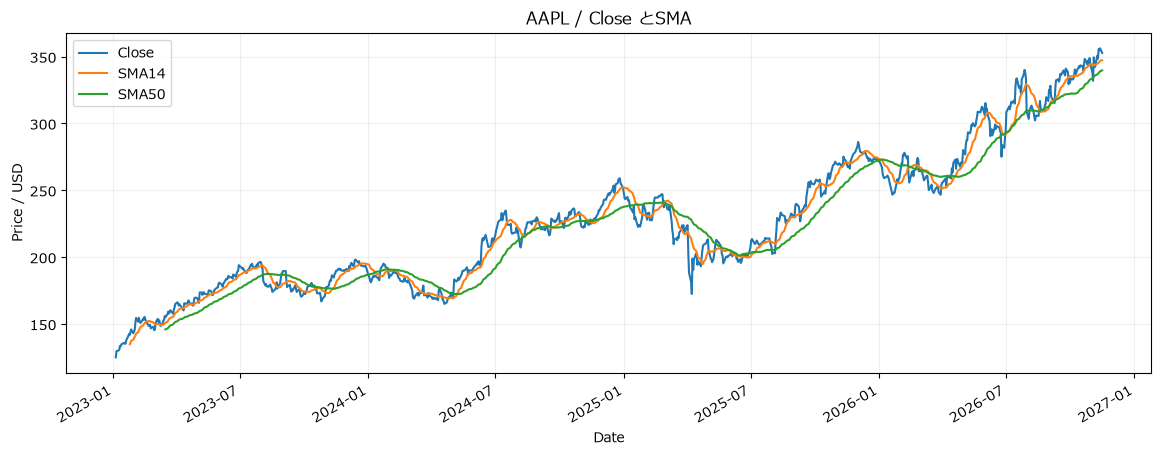

In [48]:
df_aapl[["Close", "SMA14", "SMA50"]].plot(
    figsize=(14,5),
    title="AAPL / Close とSMA"
)
plt.ylabel("Price / USD")
plt.grid(alpha=0.2)
plt.show()

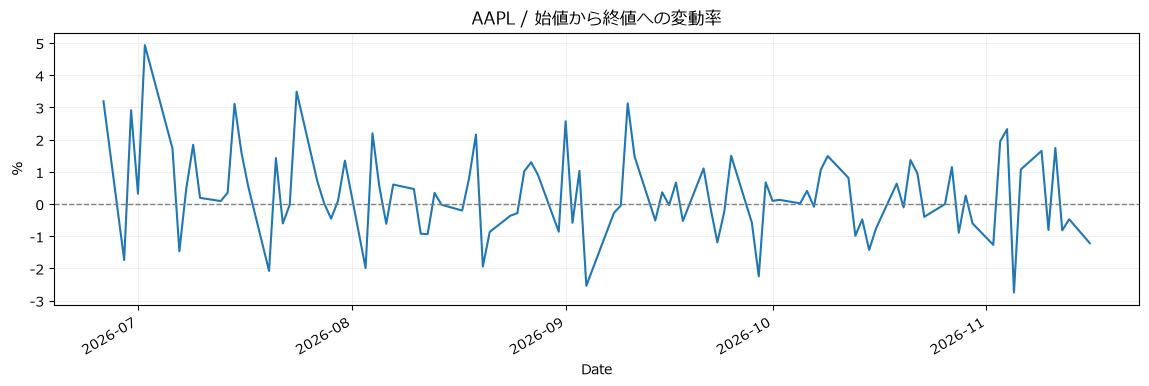

In [50]:
df_aapl["change_pct"].tail(100).plot(
    figsize=(14,4),
    title="AAPL / 始値から終値への変動率"
)

plt.ylabel("%")
plt.axhline(0, color="gray", linestyle="--", linewidth=1)

plt.grid(alpha=0.2)
plt.show()

In [55]:
df_meta = yf.download(
  "META",
  start ="2023-01-05",
  auto_adjust = False,
  multi_level_index=False,
  progress=False,
  timeout=20
)
df_gold = yf.download(
  "GC=F",
  start ="2023-01-05",
  auto_adjust = False,
  multi_level_index=False,
  progress=False,
  timeout=20
)

In [56]:
for df in (df_meta, df_gold):
    # 列が MultiIndex (yfinance の複数階層) ならフラットにする
    if isinstance(df.columns, pd.MultiIndex):  # colums から修正
        # "Close" が0階層目にあれば0 なければ最後の階層を使う
        level = (0 if "Close" in df.columns.get_level_values(0) else -1)  # in を追加
        df.columns = df.columns.get_level_values(level)

    # 始値から終値までの変化率 (%) を計算する
    df["change_pct"] = (
        (df["Close"] - df["Open"]) / df["Open"].replace(0, float("nan")) * 100
    )

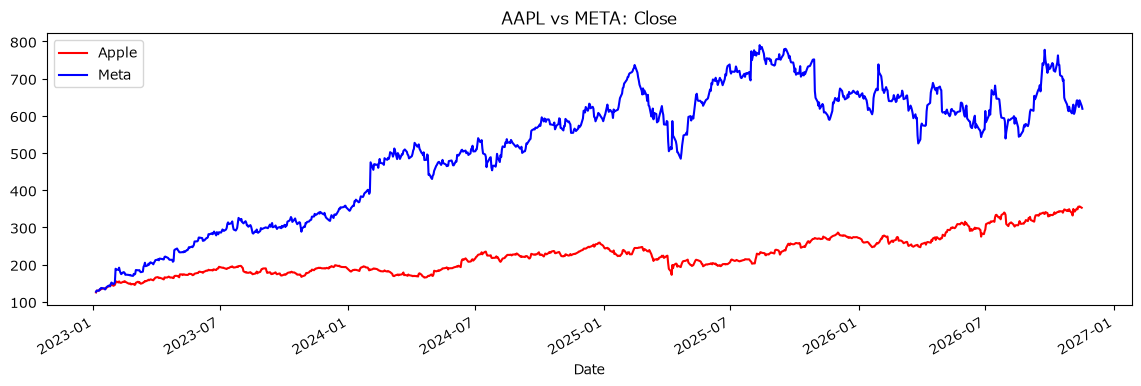

In [62]:
ax = df_aapl["Close"].plot(
    figsize=(14,  4),
    label="Apple",
    color="red"
)

ax = df_meta["Close"].plot(
    ax=ax,
    label="Meta",
    color="blue"
)

plt.title("AAPL vs META: Close")
plt.legend()
plt.show()


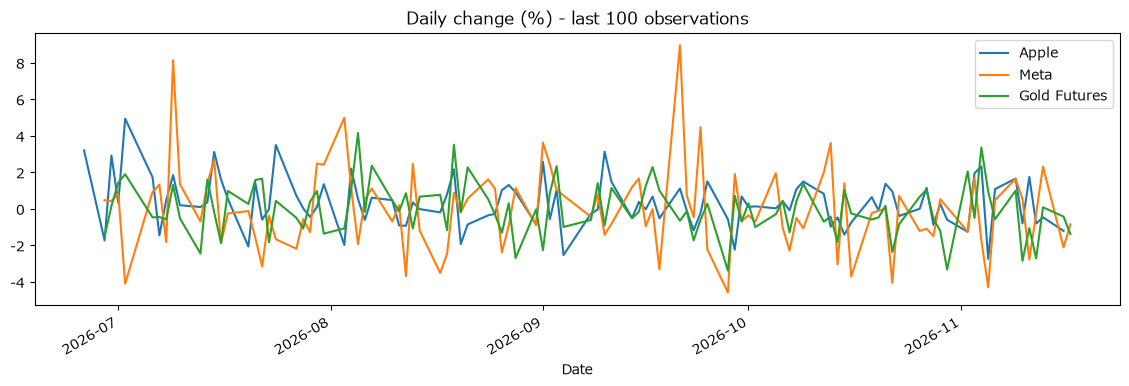

In [64]:
ax =df_aapl["change_pct"].tail(100).plot(
    figsize=(14, 4),
    label="Apple")
df_meta["change_pct"].tail(100).plot(
    ax=ax,label="Meta")
df_gold["change_pct"].tail(100).plot(
    ax=ax,label="Gold Futures")
plt.title("Daily change (%) - last 100 observations")
plt.legend()
plt.show()

In [67]:
HORIZON = 30
df_train = df_aapl.copy()
df_train["label"] = df_train["Close"].shift(-HORIZON)
display(df_train[["Close", "SMA14", "label"]].tail()
       )

,Close,SMA14,label
Date,,,
2026-11-10,348.510010,344.985718,NaN
2026-11-11,355.630005,345.515004,NaN
2026-11-12,354.880005,346.025718,NaN
2026-11-13,356.269989,346.908574,NaN
2026-11-16,352.779999,347.314287,NaN


In [68]:
features = price_cols
known = df_train.iloc[:-HORIZON].dropna(
    subset = ["label", *features]
)

In [71]:
train, test = train_test_split(
    known,
    test_size=0.2,
    shuffle=False
)
# train.shape

(752, 10)

In [72]:
train =train.iloc[:-HORIZON]
# train

,Adj Close,Close,High,Low,Open,Volume,SMA14,SMA50,change_pct,label
Date,,,,,,,,,,
2023-01-05,122.734360,125.019997,127.769997,124.760002,127.129997,80962700,NaN,NaN,-1.659719,152.550003
2023-01-06,127.250267,129.619995,130.289993,124.889999,126.010002,87754700,NaN,NaN,2.864846,148.479996
2023-01-09,127.770561,130.149994,133.410004,129.889999,130.470001,70790800,NaN,NaN,-0.245273,148.910004
2023-01-10,128.339966,130.729996,131.259995,128.119995,130.259995,63896200,NaN,NaN,0.360818,149.399994
2023-01-11,131.049545,133.490005,133.509995,130.460007,131.250000,69458900,NaN,NaN,1.706671,146.710007
...,...,...,...,...,...,...,...,...,...,...
2025-11-13,272.002411,272.950012,276.700012,272.089996,274.109985,49602800,270.560715,255.272000,-0.423178,273.760010
2025-11-14,271.464233,272.410004,275.959991,269.600006,271.049988,47431300,270.817858,255.926400,0.501758,273.079987
2025-11-17,266.531433,267.459991,270.489990,265.730011,268.820007,45018300,270.707857,256.517999,-0.505921,271.859985


In [73]:
if len(train) < 40 or len(test) < 10:
    raise ValueError("学習・検証に使える株価データが不足しています")

In [78]:
from sklearn import set_config
set_config(display='text')

model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)
# model
# features

['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

In [80]:
model.fit(train[features], train["label"])
pred_test = model.predict(test[features])
# pred=test

In [81]:
actual_up = test["label"] > test["Close"]
# actual_up

Date
2026-01-06    False
2026-01-07     True
2026-01-08     True
2026-01-09     True
2026-01-12     True
              ...  
2026-09-29     True
2026-09-30     True
2026-10-01     True
2026-10-02     True
2026-10-05     True
Length: 188, dtype: bool

In [82]:
pred_up = pred_test > test["Close"].to_numpy()
# pred_up

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False, False,  True,  True, False, False,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False, False, False, False,
       False, False,

In [86]:
# 実際の上昇と予測の上昇を比べて正解率を出す
accuracy = accuracy_score(actual_up, pred_up) 
print(f"検証の正解率： {accuracy:.2%}") 

検証の正解率： 64.89%


In [87]:
# known

,Adj Close,Close,High,Low,Open,Volume,SMA14,SMA50,change_pct,label
Date,,,,,,,,,,
2023-01-05,122.734360,125.019997,127.769997,124.760002,127.129997,80962700,NaN,NaN,-1.659719,152.550003
2023-01-06,127.250267,129.619995,130.289993,124.889999,126.010002,87754700,NaN,NaN,2.864846,148.479996
2023-01-09,127.770561,130.149994,133.410004,129.889999,130.470001,70790800,NaN,NaN,-0.245273,148.910004
2023-01-10,128.339966,130.729996,131.259995,128.119995,130.259995,63896200,NaN,NaN,0.360818,149.399994
2023-01-11,131.049545,133.490005,133.509995,130.460007,131.250000,69458900,NaN,NaN,1.706671,146.710007
...,...,...,...,...,...,...,...,...,...,...
2026-09-29,329.149902,329.399994,337.089996,328.700012,336.970001,38478000,334.952857,321.981400,-2.246493,348.510010
2026-09-30,332.767151,333.019989,339.500000,330.140015,330.799988,49988600,335.413570,322.087000,0.671101,355.630005
2026-10-01,330.069214,330.320007,332.480011,325.809998,330.000000,36306300,335.274285,322.175599,0.096972,354.880005


In [88]:
model.fit(known[features], known["label"])

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])

In [90]:
future_x = df_train.iloc[-HORIZON:][features]
# features

['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

In [93]:
if future_x.isna().any().any():# numpy()
    raise ValueError("予測用データに欠損値があります")

In [96]:
values = model.predict(future_x)
# values

array([337.63497681, 339.2490027 , 341.33608225, 337.20198958,
       341.96557515, 342.76933422, 345.00161554, 344.23399101,
       344.85103181, 343.40722004, 342.24621371, 343.37138159,
       347.27647627, 347.80325032, 344.74124695, 346.47205304,
       346.3593405 , 349.22361018, 341.93733692, 341.27876485,
       333.5857169 , 344.85658319, 344.40226634, 342.16883889,
       347.92437003, 347.65261855, 351.4997086 , 358.57474172,
       359.55970703, 357.42582736])

In [101]:
# 直近90日に土日のデータが4日以上あれば、週末も含める (暗号資産とかのとき)
weekends = (df_aapl.index[-90:].dayofweek >= 5).sum() >= 4

# 予測する日付の一覧を作る (データの最終日の翌日から始める)
feature_days = pd.date_range(
    start=df_aapl.index[-1] + pd.Timedelta(days=1), 
    periods=HORIZON,
    freq="D" if weekends else "B",
)

In [105]:
# 予測値と日付を1つの表にまとめる
future = pd.DataFrame(
    {"Predict": values},   # 予測値の列
    index=feature_days,  
)
display(future)

,Predict
2026-11-17,337.634977
2026-11-18,339.249003
2026-11-19,341.336082
2026-11-20,337.201990
2026-11-23,341.965575
2026-11-24,342.769334
2026-11-25,345.001616
2026-11-26,344.233991
2026-11-27,344.851032
2026-11-30,343.407220


In [108]:
# 週末を含めたかどうかを表示する
print(
    "予測の日付:",
    "暦日" if weekends else "平日換算（祝日は未考慮）", 
)


予測の日付: 平日換算（祝日は未考慮）


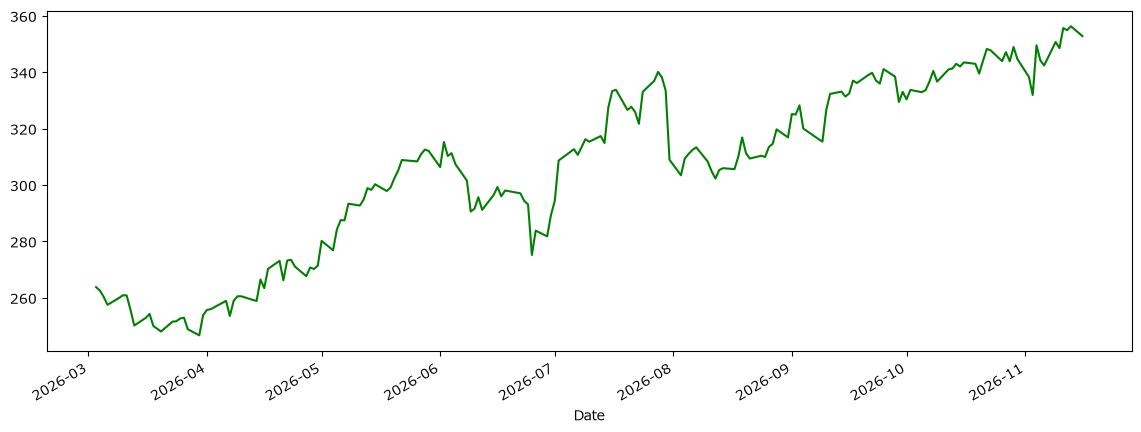

In [109]:
# 直近180日の終値を緑の線で描く
ax = df_aapl["Close"].tail(180).plot(
    figsize=(14, 5),
    label="実際の終値",  # 凡例に出る名前
    color="green",
)

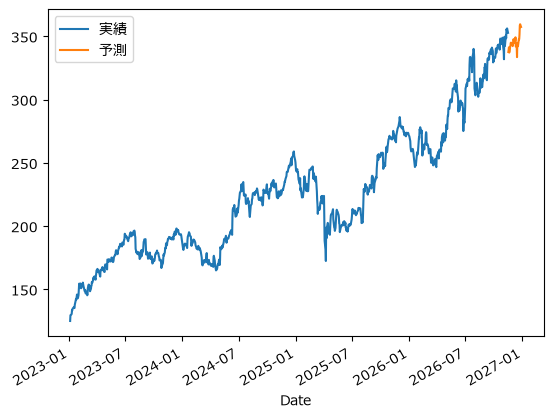

In [116]:
ax = df_aapl["Close"].plot(label="実績")
future["Predict"].plot(ax=ax, label="予測")
plt.legend()

C:\Users\WebEn6\AppData\Local\Temp\ipykernel_13784\4074349539.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


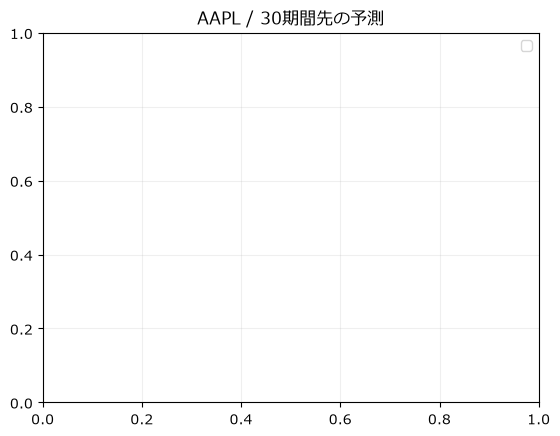

In [119]:
# 予測した終値をオレンジの線で重ねる
future["Predict"].plot(
    ax=ax,
    label="予測終値",  # 終寝から修正
    color="orange",
)
plt.title("AAPL / 30期間先の予測")
plt.legend()
plt.grid(alpha=0.2)
plt.show()